In [7]:
import os, json
import pandas as pd
pd.set_option("display.max_colwidth", 200)
#pd.set_option("display.width", 500)  # adjusts total line width before wrapping
import numpy as np
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe
from google.oauth2 import service_account # based on google-auth library
import matplotlib.pyplot as plt
import duckdb
from transformers import AutoTokenizer, AutoModel
import importlib
from sklearn.manifold import TSNE
import ast


conn = duckdb.connect('/srv/data/grela/grela_v0.6.duckdb', read_only=True)

In [8]:
# our own embedding functions
import helper_functions
importlib.reload(helper_functions)

<module 'helper_functions' from '/home/jupyter-vojta/notebooks/enemy-christianity/scripts/helper_functions.py'>

In [9]:
try:
    file_data = json.load(open(os.path.expanduser("~/ServiceAccountsKey.json")))
    # (2) transform the content into crendentials object
    credentials = service_account.Credentials.from_service_account_info(file_data)
# (3) specify your usage of the credentials
    scoped_credentials = credentials.with_scopes(['https://spreadsheets.google.com/feeds', 'https://www.googleapis.com/auth/drive'])
# (4) use the constrained credentials for authentication of gspread package
    gc = gspread.Client(auth=scoped_credentials)
    enemy_gs = gc.open_by_url("https://docs.google.com/spreadsheets/d/1ENbQuxY_U8W0sKHtiN348AS7KS9pxKjnbSg18KuUs7U/edit?usp=sharing")
except:
    pass

## Load annotated NT verses

In [10]:
biblical_verses = get_as_dataframe(enemy_gs.worksheet("biblical-verses"))
biblical_verses["chapter"] = biblical_verses["chapter"].astype(int).astype(str)
biblical_verses["verse"] = biblical_verses["verse"].astype(int).astype(str)

In [11]:
biblical_verses.shape

(645, 13)

In [12]:
biblical_verses.head(10)

,book_code,book_name,chapter,verse,primary_category,additional_categories,cat1_polemical terms,cat2_polemical terms,cat3_polemical terms,cat4_polemical terms,cat5_polemical terms,cat6_polemical terms,cat7_polemical terms
0,lagt_tlg0031.tlg013,1 Thessalonians,2,2,5.0,NaN,NaN,NaN,NaN,NaN,"ὑβρίζω, προπάσχω, ἀγών",NaN,NaN
1,lagt_tlg0031.tlg013,1 Thessalonians,2,3,2.0,NaN,NaN,"πλάνη, ἀκαθαρσία, δόλος",NaN,NaN,NaN,NaN,NaN
2,lagt_tlg0031.tlg013,1 Thessalonians,2,5,2.0,NaN,NaN,"κολακεία, πρόφασις, πλεονεξία",NaN,NaN,NaN,NaN,NaN
3,lagt_tlg0031.tlg013,1 Thessalonians,2,14,5.0,NaN,NaN,NaN,NaN,NaN,πάσχω,NaN,NaN
4,lagt_tlg0031.tlg013,1 Thessalonians,2,15,5.0,NaN,NaN,NaN,NaN,NaN,"ἀποκτείνω, ἐκδιώκω, ἐναντίος",NaN,NaN
5,lagt_tlg0031.tlg013,1 Thessalonians,2,16,5.0,7,NaN,NaN,NaN,NaN,"κωλύω, ἁμαρτία, ὀργή",NaN,NaN
6,lagt_tlg0031.tlg013,1 Thessalonians,2,18,7.0,5,NaN,NaN,NaN,NaN,NaN,NaN,ἐγκόπτω
7,lagt_tlg0031.tlg013,1 Thessalonians,4,3,4.0,NaN,NaN,NaN,NaN,πορνεία,NaN,NaN,NaN
8,lagt_tlg0031.tlg013,1 Thessalonians,4,5,4.0,NaN,NaN,NaN,NaN,ἐπιθυμία,NaN,NaN,NaN
9,lagt_tlg0031.tlg013,1 Thessalonians,4,6,2.0,1,ἔκδικος,ὑπερβαίνω,NaN,NaN,NaN,NaN,NaN


In [13]:
biblical_verses["chapterverse"] = biblical_verses.apply(lambda row: ".".join([row["chapter"], row["verse"]]), axis=1)
biblical_verses.rename({"book_code" :"grela_id"}, axis=1, inplace=True)

In [14]:
biblical_verses.columns

Index(['grela_id', 'book_name', 'chapter', 'verse', 'primary_category',
       'additional_categories', 'cat1_polemical terms', 'cat2_polemical terms',
       'cat3_polemical terms', 'cat4_polemical terms', 'cat5_polemical terms',
       'cat6_polemical terms', 'cat7_polemical terms', 'chapterverse'],
      dtype='object')

In [15]:
# we have to normalize!!!
helper_functions.normalize_greek("ἐντυγχάνω") == "ἐντυγχάνω"

True

In [16]:
polemical_terms_nt_dict = {}
for i in range(1,8): # for each column listing polemical terms
    col = f"cat{i}_polemical terms"
    terms_list_ser = biblical_verses.loc[biblical_verses[col].notnull(), col].apply(lambda x: x.split(", "))#%% md
    polemical_terms_nt_dict["cat" + str(i)] = set([helper_functions.normalize_greek(t) for l in terms_list_ser for t in l])

In [17]:
polemical_terms_nt_dict

{'cat1': {' διάβολος',
  'Βάαλ',
  'Βεελζεβούλ',
  'Γώγ',
  'Μαγώγ',
  'Μολόχ',
  'Νικολαΐτης',
  'Σατάν',
  'Σατανᾶς',
  'αἰών',
  'αἵρεσις',
  'αὐθάδης',
  'βέβηλος',
  'βασκαίνω',
  'βδέλυγμα',
  'βδελυκτός',
  'βδελύσσομαι',
  'βλάσφημος',
  'βλασφημέω',
  'βλασφημία',
  'γέεννα',
  'γενεαλογία',
  'γοητής',
  'γραώδης',
  'δίκη',
  'δαίμων',
  'δαιμονίζομαι',
  'δαιμόνιον',
  'διάβολος',
  'διακρίνω',
  'διαστρέφω',
  'διστάζω',
  'δράκων',
  'εἰδωλολάτρης',
  'εἰδωλολατρία',
  'εἰδωλόθυτον',
  'εἰκών',
  'εἴδωλον',
  'ζόφος',
  'θήρα',
  'θεοστυγής',
  'θηρίον',
  'θλῖψις',
  'θύμος',
  'καθεύδω',
  'κακολογέω',
  'κατάνυξις',
  'κατάρα',
  'καταδικάζω',
  'κατακλυσμός',
  'κατακρίνω',
  'καταναθεμα',
  'καταράομαι',
  'καταστροφή',
  'κατατομή',
  'καταφθείρω',
  'κατείδωλος',
  'καυστηριάζω',
  'κοινός',
  'κοινόω',
  'κολάζω',
  'κρίμα',
  'κρίνω',
  'κρίσις',
  'κόσμος',
  'λατρεύω',
  'μάγος',
  'μάταιος',
  'μαγεύω',
  'ματαιότης',
  'μεταλλάσσω',
  'μεταστρέφω',
  'μετατίθ

In [18]:
polemical_terms_nt_flat = []
for k, v in polemical_terms_nt_dict.items():
    polemical_terms_nt_flat.extend(v)
polemical_terms_nt_flat = list(set(polemical_terms_nt_flat))

In [19]:
len(polemical_terms_nt_flat)

636

## Ekthros coocurrents

In [21]:
all_freqs = get_as_dataframe(enemy_gs.worksheet("all_freqs_grelaV6"))
# change type to int
all_freqs["label"] = all_freqs["label"].fillna(-1).astype(int)#%%
all_freqs.sample(10)

,word,count,corpus,label
143,μετέχω,1558.0,pagan_0_300,-1
7004,ζῷον,700.0,christian_0_300,-1
595,ὀρθός,2100.0,pagan_0_300,-1
6192,γεννάω,1082.0,christian_0_300,-1
6178,ὄνομα,2680.0,christian_300_600,-1
3972,οἶνος,267.0,pagan_300_600,-1
7471,παρουσία,243.0,christian_0_300,-1
11438,ἁμαρτάνω,488.0,christian_300_600,7
9098,διαθήκη,396.0,christian_300_600,-1
8531,πατήρ,4436.0,christian_0_300,-1


In [22]:
polemical_terms_coocs_dict = {}
for n in range(1,8):
    polemical_terms_coocs_dict["cat" + str(n)] = [helper_functions.normalize_greek(w) for w in all_freqs[all_freqs["label"] == n]["word"].tolist()]

In [23]:
polemical_terms_coocs_dict

{'cat1': ['σκανδαλίζω',
  'ἀπόστασις',
  'ἀρειανός',
  'σαμάρεια',
  'πλάνη',
  'δαίμων',
  'διακρίνω',
  'χωρίζω',
  'τιμωρία',
  'διάβολος',
  'διάβολος',
  'ἀποστρέφω',
  'χωρίζω',
  'ἄγαλμα',
  'ἀποστρέφω',
  'ἡσσάομαι',
  'ἀπιστέω',
  'τιμωρία',
  'κρίνω',
  'αἵρεσις',
  'κρίνω',
  'αἵρεσις',
  'φαντασία',
  'κρίνω',
  'θηρίον',
  'φαντασία',
  'δαίμων',
  'χωρίζω',
  'ὄφις',
  'ἄγαλμα',
  'σκότος',
  'σκότος',
  'ἀποστρέφω',
  'ἀποστρέφω',
  'ἀντίκειμαι',
  'θηρίον',
  'θηρίον',
  'πλάνη',
  'παραιτέομαι',
  'κολάζω',
  'διάβολος',
  'κολάζω',
  'δαίμων',
  'ἀφίστημι',
  'ᾅδης',
  'χωρίζω',
  'διάβολος',
  'θηρίον',
  'δαίμων',
  'ἀφίστημι',
  'διακρίνω',
  'ὄφις',
  'κρίνω',
  'ὄφις',
  'χωρίζω',
  'χωρίζω',
  'κρίνω',
  'κρίνω',
  'φάρμακον',
  'φάρμακον',
  'φαντασία',
  'φαντασία',
  'ἄθεος',
  'πειράω',
  'πειράω',
  'διαβάλλω',
  'δαίμων',
  'δαίμων',
  'ἀσεβής',
  'πλανάω',
  'ἀσεβής',
  'διακρίνω',
  'φάρμακον',
  'διακρίνω',
  'διακρίνω',
  'φάρμακον',
  'αἵρεσις',
  'αἵ

In [24]:
polemical_terms_coocs_flat = list(set([t for l in polemical_terms_coocs_dict.values() for t in l]))

In [25]:
len(polemical_terms_coocs_flat)

247

In [26]:
len(polemical_terms_nt_flat)

636

In [27]:
polemical_terms_all_flat = list(set(polemical_terms_coocs_flat + polemical_terms_nt_flat))

In [28]:
len(polemical_terms_all_flat)

762

## GreLa GNT tokens

In [29]:
query = """
    SELECT t.*, w.*
    FROM tokens t
    JOIN works w ON t.grela_id = w.grela_id
    WHERE w.grela_id LIKE 'lagt_tlg0031%'
"""

gnt_tokens = conn.execute(query).fetchdf()

In [30]:
len(gnt_tokens)

158318

In [31]:
gnt_tokens.head(5)

,sentence_id,grela_id,token_text,lemma,pos,ref,char_start,char_end,token_id,grela_source,...,provenience,place_publication,place_geonames,author_viaf,author_wd,author_gnd,title_viaf,subcorpus_specific_metadata,token_count,sentence_count
0,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Ἰούδας,Ἰούδας,NOUN,"{""div_section"": ""1""}",0,6,853395,lagt,...,christian,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20
1,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Ἰησοῦ,Ἰησοῦς,NOUN,"{""div_section"": ""1""}",7,12,853396,lagt,...,christian,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20
2,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Χριστοῦ,Χριστός,NOUN,"{""div_section"": ""1""}",13,20,853397,lagt,...,christian,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20
3,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,δοῦλος,δοῦλος,NOUN,"{""div_section"": ""1""}",21,27,853398,lagt,...,christian,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20
4,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,",",",",PUNCT,"{""div_section"": ""1""}",27,28,853399,lagt,...,christian,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20


In [32]:
gnt_tokens.groupby("grela_id").size()

grela_id
lagt_tlg0031.tlg001    21010
lagt_tlg0031.tlg002    12998
lagt_tlg0031.tlg003    22410
lagt_tlg0031.tlg004    18143
lagt_tlg0031.tlg005    20679
lagt_tlg0031.tlg006     8191
lagt_tlg0031.tlg007     8079
lagt_tlg0031.tlg008     5165
lagt_tlg0031.tlg009     2613
lagt_tlg0031.tlg010     2701
lagt_tlg0031.tlg011     1873
lagt_tlg0031.tlg012     1803
lagt_tlg0031.tlg013     1677
lagt_tlg0031.tlg014      926
lagt_tlg0031.tlg015     1897
lagt_tlg0031.tlg016     1469
lagt_tlg0031.tlg017      778
lagt_tlg0031.tlg018      387
lagt_tlg0031.tlg019     5680
lagt_tlg0031.tlg020     2045
lagt_tlg0031.tlg021     1930
lagt_tlg0031.tlg022     1243
lagt_tlg0031.tlg023     2444
lagt_tlg0031.tlg024      281
lagt_tlg0031.tlg025      255
lagt_tlg0031.tlg026      528
lagt_tlg0031.tlg027    11113
dtype: int64

In [33]:
def extract_chapterverse(ref_str):
    ref = ast.literal_eval(ref_str) if isinstance(ref_str, str) else ref_str
    sec = ref.get("div_section")
    if "." not in sec:
        sec = "1." + sec
    return sec
gnt_tokens["chapterverse"] = gnt_tokens["ref"].apply(extract_chapterverse)

In [34]:
gnt_tokens[(gnt_tokens["chapterverse"].str.startswith("3.14")) & (gnt_tokens["grela_id"]=="lagt_tlg0031.tlg006")]

,sentence_id,grela_id,token_text,lemma,pos,ref,char_start,char_end,token_id,grela_source,...,place_publication,place_geonames,author_viaf,author_wd,author_gnd,title_viaf,subcorpus_specific_metadata,token_count,sentence_count,chapterverse
75798,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,ὧν,ὅς,PRON,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",97,99,28836945,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75799,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,τὸ,ὁ,DET,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",100,102,28836946,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75800,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,στόμα,στόμα,NOUN,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",103,108,28836947,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75801,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,ἀρᾶς,ἀρά,NOUN,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",109,113,28836948,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75802,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,καὶ,καί,X,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",114,117,28836949,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75803,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,πικρίας,πικρία,NOUN,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",118,125,28836950,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75804,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,γέμει,γέμω,VERB,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",126,131,28836951,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14
75805,lagt_tlg0031.tlg006_68,lagt_tlg0031.tlg006,·,·,PUNCT,"{""div_chapter"": ""3"", ""div_section"": ""3.14""}",131,132,28836952,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",8191,500,3.14


In [35]:
gnt_tokens[gnt_tokens["grela_id"]=="lagt_tlg0031.tlg026"]

,sentence_id,grela_id,token_text,lemma,pos,ref,char_start,char_end,token_id,grela_source,...,place_publication,place_geonames,author_viaf,author_wd,author_gnd,title_viaf,subcorpus_specific_metadata,token_count,sentence_count,chapterverse
0,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Ἰούδας,Ἰούδας,NOUN,"{""div_section"": ""1""}",0,6,853395,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.1
1,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Ἰησοῦ,Ἰησοῦς,NOUN,"{""div_section"": ""1""}",7,12,853396,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.1
2,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,Χριστοῦ,Χριστός,NOUN,"{""div_section"": ""1""}",13,20,853397,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.1
3,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,δοῦλος,δοῦλος,NOUN,"{""div_section"": ""1""}",21,27,853398,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.1
4,lagt_tlg0031.tlg026_0,lagt_tlg0031.tlg026,",",",",PUNCT,"{""div_section"": ""1""}",27,28,853399,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523,lagt_tlg0031.tlg026_18,lagt_tlg0031.tlg026,τοὺς,ὁ,DET,"{""div_section"": ""25""}",235,239,853918,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.25
524,lagt_tlg0031.tlg026_18,lagt_tlg0031.tlg026,αἰῶνας,αἰών,NOUN,"{""div_section"": ""25""}",240,246,853919,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.25
525,lagt_tlg0031.tlg026_18,lagt_tlg0031.tlg026,·,·,PUNCT,"{""div_section"": ""25""}",246,247,853920,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.25
526,lagt_tlg0031.tlg026_19,lagt_tlg0031.tlg026,ἀμήν,ἀμήν,INTJ,"{""div_section"": ""25""}",0,4,853921,lagt,...,None,None,None,None,None,None,"{""lagt_tlg_epithet"":""[]"",""lagt_genre"":""[]"",""noscemus_place"":null,""noscemus_genre"":null,""noscemus_discipline"":null,""emlap_noscemus_id"":null}",528,20,1.25


In [36]:
def _reconstruct_by_offsets(g: pd.DataFrame) -> str:
    g = g.sort_values(["char_start", "char_end"])
    out = []
    prev_end = None
    for _, r in g.iterrows():
        s, e = int(r["char_start"]), int(r["char_end"])
        tok = str(r["token_text"])
        if prev_end is None:
            # first token of the verse
            out.append(tok)
        else:
            if s >= prev_end:
                # same segment: insert exact gap (could be zero)
                if s > prev_end:
                    out.append(" " * (s - prev_end))
            else:
                # offset reset → new segment (likely new sentence); join with single space
                out.append(" ")
            out.append(tok)
        prev_end = e
    return "".join(out).lstrip()  # remove any leading spaces if verse starts mid-sentence


def reconstruct_verse(g: pd.DataFrame) -> pd.Series:
    verse_text = _reconstruct_by_offsets(g)
    token_dicts = g.sort_values(["char_start", "char_end"]).to_dict(orient="records")
    return pd.Series({
        "verse_text": verse_text,
        "tokens": token_dicts
    })


# group by grela_id + existing chapterverse
verses = (
    gnt_tokens
    .groupby(["grela_id", "chapterverse"], sort=False)
    .apply(reconstruct_verse)
    .reset_index()
)

print(verses.shape)

(7940, 4)


/tmp/ipykernel_356315/379204977.py:37: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(reconstruct_verse)


In [37]:
verses[verses["grela_id"]=="lagt_tlg0031.tlg026"]

,grela_id,chapterverse,verse_text,tokens
0,lagt_tlg0031.tlg026,1.1,"Ἰούδας Ἰησοῦ Χριστοῦ δοῦλος, ἀδελφὸς δὲ Ἰακώβου, τοῖς ἐν θεῷ πατρὶ ἠγαπημένοις καὶ Ἰησοῦ Χριστῷ τετηρημένοις κλητοῖς·","[{'sentence_id': 'lagt_tlg0031.tlg026_0', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'Ἰούδας', 'lemma': 'Ἰούδας', 'pos': 'NOUN', 'ref': '{""div_section"": ""1""}', 'char_start': 0, 'char_end': 6..."
1,lagt_tlg0031.tlg026,1.2,ἔλεος ὑμῖν καὶ εἰρήνη καὶ ἀγάπη πληθυνθείη.,"[{'sentence_id': 'lagt_tlg0031.tlg026_1', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ἔλεος', 'lemma': 'ἔλεος', 'pos': 'NOUN', 'ref': '{""div_section"": ""2""}', 'char_start': 0, 'char_end': 5, ..."
2,lagt_tlg0031.tlg026,1.3,"ἀγαπητοί, πᾶσαν σπουδὴν ποιούμενος γράφειν ὑμῖν περὶ τῆς κοινῆς ἡμῶν σωτηρίας ἀνάγκην ἔσχον γράψαι ὑμῖν παρακαλῶν ἐπαγωνίζεσθαι τῇ ἅπαξ παραδοθείσῃ τοῖς ἁγίοις πίστει.","[{'sentence_id': 'lagt_tlg0031.tlg026_2', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ἀγαπητοί', 'lemma': 'ἀγαπητός', 'pos': 'ADJ', 'ref': '{""div_section"": ""3""}', 'char_start': 0, 'char_end'..."
3,lagt_tlg0031.tlg026,1.4,"παρεισέδυσαν γάρ τινες ἄνθρωποι, οἱ πάλαι προγεγραμμένοι εἰς τοῦτο τὸ κρίμα, ἀσεβεῖς, τὴν τοῦ θεοῦ ἡμῶν χάριτα μετατιθέντες εἰς ἀσέλγειαν καὶ τὸν μόνον δεσπότην καὶ κύριον ἡμῶν Ἰησοῦν Χριστὸν ἀρνο...","[{'sentence_id': 'lagt_tlg0031.tlg026_3', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'παρεισέδυσαν', 'lemma': 'παρεισδύνω', 'pos': 'VERB', 'ref': '{""div_section"": ""4""}', 'char_start': 0, 'ch..."
4,lagt_tlg0031.tlg026,1.5,"ὑπομνῆσαι δὲ ὑμᾶς βούλομαι, εἰδότας ἅπαξ πάντα, ὅτι κύριος λαὸν ἐκ γῆς Αἰγύπτου σώσας τὸ δεύτερον τοὺς μὴ πιστεύσαντες ἀπώλεσεν,","[{'sentence_id': 'lagt_tlg0031.tlg026_4', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ὑπομνῆσαι', 'lemma': 'ὑπομιμνῄσκω', 'pos': 'VERB', 'ref': '{""div_section"": ""5""}', 'char_start': 0, 'char..."
5,lagt_tlg0031.tlg026,1.6,ἀγγέλους τε τοὺς μὴ τηρήσαντας τὴν ἑαυτῶν ἀρχὴν ἀλλὰ ἀπολιπόντας τὸ ἴδιον οἰκητήριον εἰς κρίσιν μεγάλης ἡμέρας δεσμοῖς ἀϊδίοις ὑπὸ ζόφον τετήρηκεν·,"[{'sentence_id': 'lagt_tlg0031.tlg026_4', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ἀγγέλους', 'lemma': 'ἄγγελος', 'pos': 'NOUN', 'ref': '{""div_section"": ""6""}', 'char_start': 129, 'char_en..."
6,lagt_tlg0031.tlg026,1.7,"ὡς Σόδομα καὶ Γόμορρα καὶ αἱ περὶ αὐτὰς πόλεις, τὸν ὅμοιον τρόπον τούτοις ἐκπορνεύσασαι καὶ ἀπελθοῦσαι ὀπίσω σαρκὸς ἑτέρας, πρόκεινται δεῖγμα πυρὸς αἰωνίου δίκην ὑπέχουσαι.","[{'sentence_id': 'lagt_tlg0031.tlg026_5', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ὡς', 'lemma': 'ὡς', 'pos': 'CCONJ', 'ref': '{""div_section"": ""7""}', 'char_start': 0, 'char_end': 2, 'toke..."
7,lagt_tlg0031.tlg026,1.8,"ὁμοίως μέντοι καὶ οὗτοι ἐνυπνιαζόμενοι σάρκα μὲν μιαίνουσιν, κυριότητα δὲ ἀθετοῦσιν, δόξας δὲ βλασφημοῦσιν.","[{'sentence_id': 'lagt_tlg0031.tlg026_6', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ὁμοίως', 'lemma': 'ὅμοιος', 'pos': 'ADV', 'ref': '{""div_section"": ""8""}', 'char_start': 0, 'char_end': 6,..."
8,lagt_tlg0031.tlg026,1.9,"ὁ δὲ Μιχαὴλ ὁ ἀρχάγγελος, ὅτε τῷ διαβόλῳ διακρινόμενος διελέγετο περὶ τοῦ Μωϋσέως σώματος, οὐκ ἐτόλμησεν κρίσιν ἐπενεγκεῖν βλασφημίας, ἀλλὰ εἶπεν, ἐπιτιμήσαι σοι κύριος.","[{'sentence_id': 'lagt_tlg0031.tlg026_7', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'ὁ', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_section"": ""9""}', 'char_start': 0, 'char_end': 1, 'token_id..."
9,lagt_tlg0031.tlg026,1.10,"οὗτοι δὲ ὅσα μὲν οὐκ οἴδασιν βλασφημοῦσιν, ὅσα δὲ φυσικῶς ὡς τὰ ἄλογα ζῷα ἐπίστανται, ἐν τούτοις φθείρονται.","[{'sentence_id': 'lagt_tlg0031.tlg026_8', 'grela_id': 'lagt_tlg0031.tlg026', 'token_text': 'οὗτοι', 'lemma': 'οὗτος', 'pos': 'PRON', 'ref': '{""div_section"": ""10""}', 'char_start': 0, 'char_end': 5,..."


## Unpolemical verses sample generation

In [38]:
def get_unpolemical_verses(tokens):
    return all(token["lemma"] not in polemical_terms_all_flat for token in tokens)
verses["unpolemical"] = verses["tokens"].apply(get_unpolemical_verses)

In [39]:
len(verses)

7940

In [40]:
verses["unpolemical"].sum()

np.int64(2971)

In [41]:
verses_unpolemical_sample = verses[verses["unpolemical"]].sample(1000, random_state=42)

In [42]:
#set_with_dataframe(enemy_gs.add_worksheet("verses_unpolemical_sample1000", 1,1), verses_unpolemical_sample)

In [43]:
verses_unpolemical_sample.to_parquet("../data/verses_unpolemical_sample.parquet")

## Merge annotated verses with GreLa GNT token-based verses

In [44]:
# left join biblical_verses with verse texts
biblical_with_texts = (
    biblical_verses
    .merge(
        verses[["grela_id","chapterverse","verse_text", "tokens"]],
        on=["grela_id","chapterverse"],
        how="left"
    )
)

In [45]:
biblical_with_texts

,grela_id,book_name,chapter,verse,primary_category,additional_categories,cat1_polemical terms,cat2_polemical terms,cat3_polemical terms,cat4_polemical terms,cat5_polemical terms,cat6_polemical terms,cat7_polemical terms,chapterverse,verse_text,tokens
0,lagt_tlg0031.tlg013,1 Thessalonians,2,2,5.0,NaN,NaN,NaN,NaN,NaN,"ὑβρίζω, προπάσχω, ἀγών",NaN,NaN,2.2,ἀλλὰ προπαθόντες καὶ ὑβρισθέντες καθὼς οἴδατε ἐν Φιλίπποις ἐπαρρησιασάμεθα ἐν τῷ θεῷ ἡμῶν λαλῆσαι πρὸς ὑμᾶς τὸ εὐαγγέλιον τοῦ θεοῦ ἐν πολλῷ ἀγῶνι.,"[{'sentence_id': 'lagt_tlg0031.tlg013_6', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ἀλλὰ', 'lemma': 'ἀλλά', 'pos': 'X', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.2""}', 'char_start': 7..."
1,lagt_tlg0031.tlg013,1 Thessalonians,2,3,2.0,NaN,NaN,"πλάνη, ἀκαθαρσία, δόλος",NaN,NaN,NaN,NaN,NaN,2.3,"ἡ γὰρ παράκλησις ἡμῶν οὐκ ἐκ πλάνης οὐ δὲ ἐξ ἀκαθαρσίας οὐ δὲ ἐν δόλῳ,","[{'sentence_id': 'lagt_tlg0031.tlg013_7', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ἡ', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.3""}', 'char_start': 0, 'c..."
2,lagt_tlg0031.tlg013,1 Thessalonians,2,5,2.0,NaN,NaN,"κολακεία, πρόφασις, πλεονεξία",NaN,NaN,NaN,NaN,NaN,2.5,"οὔ τε γάρ ποτε ἐν λόγῳ κολακίας ἐγενήθημεν, καθὼς οἴδατε, οὔ τε ἐν προφάσει πλεονεξίας, θεὸς μάρτυς,","[{'sentence_id': 'lagt_tlg0031.tlg013_8', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'οὔ', 'lemma': 'οὐ', 'pos': 'ADV', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.5""}', 'char_start': 0, ..."
3,lagt_tlg0031.tlg013,1 Thessalonians,2,14,5.0,NaN,NaN,NaN,NaN,NaN,πάσχω,NaN,NaN,2.14,"ὑμεῖς γὰρ μιμηταὶ ἐγενήθητε, ἀδελφοί, τῶν ἐκκλησιῶν τοῦ θεοῦ τῶν οὐσῶν ἐν τῇ Ἰουδαίᾳ ἐν Χριστῷ Ἰησοῦ, ὅτι τὰ αὐτὰ ἐπάθετε καὶ ὑμεῖς ὑπὸ τῶν ἰδίων συμφυλετῶν καθὼς καὶ αὐτοὶ ὑπὸ τῶν Ἰουδαίων,","[{'sentence_id': 'lagt_tlg0031.tlg013_14', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ὑμεῖς', 'lemma': 'σύ', 'pos': 'PRON', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.14""}', 'char_start..."
4,lagt_tlg0031.tlg013,1 Thessalonians,2,15,5.0,NaN,NaN,NaN,NaN,NaN,"ἀποκτείνω, ἐκδιώκω, ἐναντίος",NaN,NaN,2.15,"τῶν καὶ τὸν κύριον ἀποκτεινάντων Ἰησοῦν καὶ τοὺς προφήτας, καὶ ἡμᾶς ἐκδιωξάντων, καὶ θεῷ μὴ ἀρεσκόντων, καὶ πᾶσιν ἀνθρώποις ἐναντίων,","[{'sentence_id': 'lagt_tlg0031.tlg013_14', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'τῶν', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.15""}', 'char_start': 1..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
640,lagt_tlg0031.tlg001,Matthew,27,30,5.0,NaN,NaN,NaN,NaN,NaN,"ἐμπτύω, κάλαμος, τύπτω",NaN,NaN,27.30,καὶ ἐμπτύσαντες εἰς αὐτὸν ἔλαβον τὸν κάλαμον καὶ ἔτυπτον εἰς τὴν κεφαλὴν αὐτοῦ.,"[{'sentence_id': 'lagt_tlg0031.tlg001_1498', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'X', 'ref': '{""div_chapter"": ""27"", ""div_section"": ""27.30""}', 'char_start..."
641,lagt_tlg0031.tlg001,Matthew,27,31,5.0,NaN,NaN,NaN,NaN,NaN,"ἐμπαίζω, σταυρόω",NaN,NaN,27.31,"καὶ ὅτε ἐνέπαιξαν αὐτῷ, ἐκδύσαντες αὐτὸν τὴν χλαμύδα ἐνέδυσαν αὐτὸν τὰ ἱμάτια αὐτοῦ, καὶ ἀπήγαγον αὐτὸν εἰς τὸ σταυρῶσαι.","[{'sentence_id': 'lagt_tlg0031.tlg001_1499', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'ADV', 'ref': '{""div_chapter"": ""27"", ""div_section"": ""27.31""}', 'char_sta..."
642,lagt_tlg0031.tlg001,Matthew,27,35,5.0,NaN,NaN,NaN,NaN,NaN,σταυρόω,NaN,NaN,27.35,"σταυρώσαντες δὲ αὐτὸν διεμερίσαντο τὰ ἱμάτια αὐτοῦ βαλόντες κλῆρον,","[{'sentence_id': 'lagt_tlg0031.tlg001_1504', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'σταυρώσαντες', 'lemma': 'σταυρόω', 'pos': 'VERB', 'ref': '{""div_chapter"": ""27"", ""div_section"": ""27.35..."
643,lagt_tlg0031.tlg001,Matthew,27,39,1.0,NaN,βλασφημέω,NaN,NaN,NaN,NaN,NaN,NaN,27.39,"οἱ δὲ παραπορευόμενοι ἐβλασφήμουν αὐτὸν, κινοῦντες τὰς κεφαλὰς αὐτῶν","[{'sentence_id': 'lagt_tlg0031.tlg001_1508', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'οἱ', 'lemma': 'ὁ', 'pos': 'DE

In [46]:
len(biblical_with_texts)

645

In [47]:
biblical_with_texts[biblical_with_texts["verse_text"].isna()]

,grela_id,book_name,chapter,verse,primary_category,additional_categories,cat1_polemical terms,cat2_polemical terms,cat3_polemical terms,cat4_polemical terms,cat5_polemical terms,cat6_polemical terms,cat7_polemical terms,chapterverse,verse_text,tokens
574,lagt_tlg0031.tlg001,Matthew,23,14,2.0,"1, 6",κρίμα,ὑποκριτής,NaN,NaN,NaN,"Φαρισαῖος, γραμματεύς",NaN,23.14,NaN,NaN


In [48]:
biblical_with_texts[biblical_with_texts["verse_text"].isna()]

,grela_id,book_name,chapter,verse,primary_category,additional_categories,cat1_polemical terms,cat2_polemical terms,cat3_polemical terms,cat4_polemical terms,cat5_polemical terms,cat6_polemical terms,cat7_polemical terms,chapterverse,verse_text,tokens
574,lagt_tlg0031.tlg001,Matthew,23,14,2.0,"1, 6",κρίμα,ὑποκριτής,NaN,NaN,NaN,"Φαρισαῖος, γραμματεύς",NaN,23.14,NaN,NaN


In [49]:
biblical_with_texts = biblical_with_texts[biblical_with_texts["verse_text"].notna()].copy()
biblical_with_texts = biblical_with_texts[biblical_with_texts["primary_category"].notna()].copy()
len(biblical_with_texts)

643

## Merge polemical and unpolemical

In [50]:
verses_merged = pd.concat([biblical_with_texts, verses_unpolemical_sample], ignore_index=True)#%% md

In [51]:
len(verses_merged)

1643

In [52]:
verses_merged["lemmatized_sentence"] = verses_merged["tokens"].apply(lambda x: " ".join([t["lemma"] for t in x if t["pos"] in ["NOUN", "VERB", "PROPN", "ADJ"]]))

In [53]:
verses_merged["lemmatized_sentence"][:10].tolist()

['προπάσχω ὑβρίζω οἶδα Φίλιπποι παρρησιάζομαι θεός λαλέω εὐαγγέλιον θεός πολύς ἀγών',
 'παράκλησις πλάνη ἀκαθαρσία δόλος',
 'λόγος κολακεία γίγνομαι οἶδα πρόφασις πλεονεξία θεός μάρτυς',
 'μιμητής γίγνομαι ἀδελφός ἐκκλησία θεός εἰμί Ἰουδαία Χριστός Ἰησοῦς πάσχω ἴδιος συμφυλέτης Ἰουδαῖος',
 'κύριος ἀποκτείνω Ἰησοῦς προφήτης ἐκδιώκω θεός ἀρέσκω πᾶς ἄνθρωπος ἐναντίος',
 'φθάνω ὀργή τέλος κωλύω ἔθνος λαλέω σῴζω ἀναπληρόω ἁμαρτία',
 'ἐθέλω ἔρχομαι Παῦλος ἐγκόπτω Σατανᾶς',
 'εἰμί θέλημα θεός ἁγιασμός ἀπέχω πορνεία',
 'πάθος ἐπιθυμία ἔθνος οἶδα θεός',
 'ὑπερβαίνω πλεονεκτέω πρᾶγμα ἀδελφός ἔκδικος κύριος πᾶς προλέγω διαμαρτύρομαι']

In [54]:
verses_merged.head(10)

,grela_id,book_name,chapter,verse,primary_category,additional_categories,cat1_polemical terms,cat2_polemical terms,cat3_polemical terms,cat4_polemical terms,cat5_polemical terms,cat6_polemical terms,cat7_polemical terms,chapterverse,verse_text,tokens,unpolemical,lemmatized_sentence
0,lagt_tlg0031.tlg013,1 Thessalonians,2,2,5.0,NaN,NaN,NaN,NaN,NaN,"ὑβρίζω, προπάσχω, ἀγών",NaN,NaN,2.2,ἀλλὰ προπαθόντες καὶ ὑβρισθέντες καθὼς οἴδατε ἐν Φιλίπποις ἐπαρρησιασάμεθα ἐν τῷ θεῷ ἡμῶν λαλῆσαι πρὸς ὑμᾶς τὸ εὐαγγέλιον τοῦ θεοῦ ἐν πολλῷ ἀγῶνι.,"[{'sentence_id': 'lagt_tlg0031.tlg013_6', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ἀλλὰ', 'lemma': 'ἀλλά', 'pos': 'X', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.2""}', 'char_start': 7...",NaN,προπάσχω ὑβρίζω οἶδα Φίλιπποι παρρησιάζομαι θεός λαλέω εὐαγγέλιον θεός πολύς ἀγών
1,lagt_tlg0031.tlg013,1 Thessalonians,2,3,2.0,NaN,NaN,"πλάνη, ἀκαθαρσία, δόλος",NaN,NaN,NaN,NaN,NaN,2.3,"ἡ γὰρ παράκλησις ἡμῶν οὐκ ἐκ πλάνης οὐ δὲ ἐξ ἀκαθαρσίας οὐ δὲ ἐν δόλῳ,","[{'sentence_id': 'lagt_tlg0031.tlg013_7', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ἡ', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.3""}', 'char_start': 0, 'c...",NaN,παράκλησις πλάνη ἀκαθαρσία δόλος
2,lagt_tlg0031.tlg013,1 Thessalonians,2,5,2.0,NaN,NaN,"κολακεία, πρόφασις, πλεονεξία",NaN,NaN,NaN,NaN,NaN,2.5,"οὔ τε γάρ ποτε ἐν λόγῳ κολακίας ἐγενήθημεν, καθὼς οἴδατε, οὔ τε ἐν προφάσει πλεονεξίας, θεὸς μάρτυς,","[{'sentence_id': 'lagt_tlg0031.tlg013_8', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'οὔ', 'lemma': 'οὐ', 'pos': 'ADV', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.5""}', 'char_start': 0, ...",NaN,λόγος κολακεία γίγνομαι οἶδα πρόφασις πλεονεξία θεός μάρτυς
3,lagt_tlg0031.tlg013,1 Thessalonians,2,14,5.0,NaN,NaN,NaN,NaN,NaN,πάσχω,NaN,NaN,2.14,"ὑμεῖς γὰρ μιμηταὶ ἐγενήθητε, ἀδελφοί, τῶν ἐκκλησιῶν τοῦ θεοῦ τῶν οὐσῶν ἐν τῇ Ἰουδαίᾳ ἐν Χριστῷ Ἰησοῦ, ὅτι τὰ αὐτὰ ἐπάθετε καὶ ὑμεῖς ὑπὸ τῶν ἰδίων συμφυλετῶν καθὼς καὶ αὐτοὶ ὑπὸ τῶν Ἰουδαίων,","[{'sentence_id': 'lagt_tlg0031.tlg013_14', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ὑμεῖς', 'lemma': 'σύ', 'pos': 'PRON', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.14""}', 'char_start...",NaN,μιμητής γίγνομαι ἀδελφός ἐκκλησία θεός εἰμί Ἰουδαία Χριστός Ἰησοῦς πάσχω ἴδιος συμφυλέτης Ἰουδαῖος
4,lagt_tlg0031.tlg013,1 Thessalonians,2,15,5.0,NaN,NaN,NaN,NaN,NaN,"ἀποκτείνω, ἐκδιώκω, ἐναντίος",NaN,NaN,2.15,"τῶν καὶ τὸν κύριον ἀποκτεινάντων Ἰησοῦν καὶ τοὺς προφήτας, καὶ ἡμᾶς ἐκδιωξάντων, καὶ θεῷ μὴ ἀρεσκόντων, καὶ πᾶσιν ἀνθρώποις ἐναντίων,","[{'sentence_id': 'lagt_tlg0031.tlg013_14', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'τῶν', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.15""}', 'char_start': 1...",NaN,κύριος ἀποκτείνω Ἰησοῦς προφήτης ἐκδιώκω θεός ἀρέσκω πᾶς ἄνθρωπος ἐναντίος
5,lagt_tlg0031.tlg013,1 Thessalonians,2,16,5.0,7,NaN,NaN,NaN,NaN,"κωλύω, ἁμαρτία, ὀργή",NaN,NaN,2.16,ἔφθασεν δὲ ἐπ αὐτοὺς ἡ ὀργὴ εἰς τέλος. ...,"[{'sentence_id': 'lagt_tlg0031.tlg013_15', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'ἔφθασεν', 'lemma': 'φθάνω', 'pos': 'VERB', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.16""}', 'char_...",NaN,φθάνω ὀργή τέλος κωλύω ἔθνος λαλέω σῴζω ἀναπληρόω ἁμαρτία
6,lagt_tlg0031.tlg013,1 Thessalonians,2,18,7.0,5,NaN,NaN,NaN,NaN,NaN,NaN,ἐγκόπτω,2.18,"διότι ἠθελήσαμεν ἐλθεῖν πρὸς ὑμᾶς, ἐγὼ μὲν Παῦλος καὶ ἅπαξ καὶ δίς, καὶ ἐνέκοψεν ἡμᾶς ὁ σατανᾶς.","[{'sentence_id': 'lagt_tlg0031.tlg013_17', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'διότι', 'lemma': 'διότι', 'pos': 'ADV', 'ref': '{""div_chapter"": ""2"", ""div_section"": ""2.18""}', 'char_sta...",NaN,ἐθέλω ἔρχομαι Παῦλος ἐγκόπτω Σατανᾶς
7,lagt_tlg0031.tlg013,1 Thessalonians,4,3,4.0,NaN,NaN,NaN,NaN,πορνεία,NaN,NaN,NaN,4.3,"τοῦτο γάρ ἐστιν θέλημα τοῦ θεοῦ, ὁ ἁγιασμὸς ὑμῶν, ἀπέχεσθαι ὑμᾶς ἀπὸ τῆς πορνείας,","[{'sentence_id': 'lagt_tlg0031.tlg013_31', 'grela_id': 'lagt_tlg0031.tlg013', 'token_text': 'τοῦτο', 'lemma'

## Annotated sentences with ekthros

In [55]:
enemy_annotations = pd.read_parquet("../data/enemy-annotations_tokens.parquet")

In [91]:
enemy_annotations["lemmatized_sentence"] = enemy_annotations["tokens"].apply(lambda x: " ".join([t["lemma"] for t in x if t["pos"] in ["n", "v", "a"]]))


In [56]:
enemy_annotations["lagt_provenience"].value_counts()

lagt_provenience
christian    500
pagan        500
Name: count, dtype: int64

In [93]:
enemy_annotations["polemical_category_first"]

np.int64(684)

In [98]:
enemy_annotations["unpolemical"] = enemy_annotations["polemical_category_first"].apply(lambda x: x not in [str(i) for i in range(1,8)])

In [99]:
enemy_annotations["unpolemical"].value_counts()

unpolemical
False    684
True     316
Name: count, dtype: int64

## Read grouped for a random sample of nonpolemical sentences

In [57]:
grouped = pd.read_pickle('../data/large-data/grouped_df.pkl')

In [70]:
grouped = grouped[~grouped["grela_id"].str.startswith("lagt_tlg0031")]

In [60]:
grouped["unpolemical"] = grouped["tokens"].apply(get_unpolemical_verses)

In [71]:
len(grouped)

991334

In [74]:
grouped_unpolemical = grouped[grouped["unpolemical"]]
grouped_unpolemical["provenience"].value_counts()

provenience
pagan        369783
christian    138308
Name: count, dtype: int64

In [75]:
grouped_unpolemical_sample = (
    grouped_unpolemical.groupby("provenience", group_keys=False)
      .apply(lambda g: g.sample(n=500, replace=False, random_state=42))
      .sample(frac=1, random_state=42)  # shuffle the combined sample
      .reset_index(drop=True)
)
grouped_unpolemical_sample["provenience"].value_counts()

/tmp/ipykernel_356315/1265746769.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=500, replace=False, random_state=42))


provenience
pagan        500
christian    500
Name: count, dtype: int64

In [104]:
grouped_unpolemical_sample["primary_category"] = -1

In [77]:
grouped_unpolemical_sample["lemmatized_sentence"] = grouped_unpolemical_sample["tokens"].apply(lambda x: " ".join([t["lemma"] for t in x if t["pos"] in ["NOUN", "VERB", "PROPN", "ADJ"]]))

Index(['grela_id', 'sentence_id', 'sentence_position', 'sent_text', 'tokens',
       'author', 'title', 'not_before', 'not_after', 'provenience',
       'enemy_subcorpus', 'lemma_sentence', 'unpolemical',
       'lemmatized_sentence'],
      dtype='object')

## Merge training data

In [79]:
verses_merged.columns

Index(['grela_id', 'book_name', 'chapter', 'verse', 'primary_category',
       'additional_categories', 'cat1_polemical terms', 'cat2_polemical terms',
       'cat3_polemical terms', 'cat4_polemical terms', 'cat5_polemical terms',
       'cat6_polemical terms', 'cat7_polemical terms', 'chapterverse',
       'verse_text', 'tokens', 'unpolemical', 'lemmatized_sentence'],
      dtype='object')

In [123]:
verses_renamed = verses_merged.rename(columns={"verse_text" : "sent_text"})[["grela_id", "sent_text", "lemmatized_sentence", "tokens", "unpolemical", "primary_category"]].reset_index(drop=True).copy()
verses_renamed["sent_source"] = "verses"
verses_renamed.sample(10, random_state=42)

,grela_id,sent_text,lemmatized_sentence,tokens,unpolemical,primary_category,sent_source
677,lagt_tlg0031.tlg006,ὁ γὰρ ἐν τούτῳ δουλεύων τῷ Χριστῷ εὐάρεστος τῷ θεῷ καὶ δόκιμος τοῖς ἀνθρώποις.,δουλεύω Χριστός εὐάρεστος θεός δόκιμος ἄνθρωπος,"[{'sentence_id': 'lagt_tlg0031.tlg006_431', 'grela_id': 'lagt_tlg0031.tlg006', 'token_text': 'ὁ', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""14"", ""div_section"": ""14.18""}', 'char_start': ...",True,NaN,verses
1100,lagt_tlg0031.tlg010,τὸ δὲ ἀνέβη τί ἐστιν εἰ μὴ ὅτι καὶ κατέβη εἰς τὰ κατώτερα τῆς γῆς;,ἀναβαίνω εἰμί καταβαίνω κατώτερος γῆ,"[{'sentence_id': 'lagt_tlg0031.tlg010_31', 'grela_id': 'lagt_tlg0031.tlg010', 'token_text': 'τὸ', 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_chapter"": ""4"", ""div_section"": ""4.9""}', 'char_start': 0, ...",True,NaN,verses
1309,lagt_tlg0031.tlg004,καὶ ὁ θεωρῶν ἐμὲ θεωρεῖ τὸν πέμψαντά με.,θεωρέω θεωρέω πέμπω,"[{'sentence_id': 'lagt_tlg0031.tlg004_981', 'grela_id': 'lagt_tlg0031.tlg004', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'X', 'ref': '{""div_chapter"": ""12"", ""div_section"": ""12.45""}', 'char_start'...",True,NaN,verses
607,lagt_tlg0031.tlg001,καὶ ἀμὴνἐσθιόντων λέγω ὑμῖναὐτῶν ὅτι εἷς εἶπεν ἐξ·ὑμῶν παραδώσει με.,ἐσθίω λέγω λέγω παραδίδωμι,"[{'sentence_id': 'lagt_tlg0031.tlg001_1335', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'ADV', 'ref': '{""div_chapter"": ""26"", ""div_section"": ""26.21""}', 'char_sta...",NaN,5.0,verses
1395,lagt_tlg0031.tlg003,"καὶ ὅτι ὁ ἐάν κύριος τις ὑμᾶς αὐτοῦ ἐρωτᾷ χρείαν , διὰ ἔχει τί.λύετε, οὕτως ἐρεῖτε·",κύριος ἐρωτάω χρεία ἔχω λύω λέγω,"[{'sentence_id': 'lagt_tlg0031.tlg003_1286', 'grela_id': 'lagt_tlg0031.tlg003', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'ADV', 'ref': '{""div_chapter"": ""19"", ""div_section"": ""19.31""}', 'char_sta...",True,NaN,verses
1034,lagt_tlg0031.tlg006,οὕτως οὖν καὶ ἐν τῷ νῦν καιρῷ λεῖμμα κατ ἐκλογὴν χάριτος γέγονεν·,καιρός λεῖμμα ἐκλογή χάρις γίγνομαι,"[{'sentence_id': 'lagt_tlg0031.tlg006_315', 'grela_id': 'lagt_tlg0031.tlg006', 'token_text': 'οὕτως', 'lemma': 'οὕτως', 'pos': 'ADV', 'ref': '{""div_chapter"": ""11"", ""div_section"": ""11.5""}', 'char_s...",True,NaN,verses
841,lagt_tlg0031.tlg002,"καὶ ἐπελάθοντο λαβεῖν ἄρτους, καὶ εἰ μὴ ἕνα ἄρτον οὐκ εἶχον μεθ ἑαυτῶν ἐν τῷ πλοίῳ.",ἐπιλανθάνω λαμβάνω ἄρτος ἄρτος ἔχω πλοῖον,"[{'sentence_id': 'lagt_tlg0031.tlg002_416', 'grela_id': 'lagt_tlg0031.tlg002', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'ADV', 'ref': '{""div_chapter"": ""8"", ""div_section"": ""8.14""}', 'char_start'...",True,NaN,verses
1559,lagt_tlg0031.tlg007,"γρηγορεῖτε, στήκετε ἐν τῇ πίστει, ἀνδρίζεσθε, κραταιοῦσθε·",γρηγορέω στήκω πίστις ἀνδρίζω κραταιόω,"[{'sentence_id': 'lagt_tlg0031.tlg007_543', 'grela_id': 'lagt_tlg0031.tlg007', 'token_text': 'γρηγορεῖτε', 'lemma': 'γρηγορέω', 'pos': 'VERB', 'ref': '{""div_chapter"": ""16"", ""div_section"": ""16.13""}...",True,NaN,verses
1240,lagt_tlg0031.tlg002,καὶ ἔφαγον πάντες καὶ ἐχορτάσθησαν·,ἐσθίω πᾶς χορτάζω,"[{'sentence_id': 'lagt_tlg0031.tlg002_327', 'grela_id': 'lagt_tlg0031.tlg002', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'ADV', 'ref': '{""div_chapter"": ""6"", ""div_section"": ""6.42""}', 'char_start'...",True,NaN,verses
271,lagt_tlg0031.tlg005,"μετανόησον οὖν ἀπὸ τῆς κακίας σου ταύτης, καὶ δεήθητι τοῦ κυρίου εἰ ἄρα ἀφεθήσεταί σοι ἡ ἐπίνοια τῆς καρδίας σου·",μετανοέω κακία δέω κύριος ἀφίημι ἐπίνοια καρδία,"[{'sentence_id': 'lagt_tlg0031.tlg005_266', 'grela_id': 'lagt_tlg0031.tlg005', 'token_text': 'μετανόησον', 'lemma': 'μετανοέω', 'pos': 'VERB', 'ref': '{""div_chapter"": ""8"", ""div_section"": ""8.22""}',...",NaN,4.0,verses


In [124]:
verses_renamed["primary_category"] = (
    verses_renamed["primary_category"].astype("Int64")
)
verses_renamed["primary_category"] = verses_renamed["primary_category"].fillna(-1)


In [127]:
verses_renamed["unpolemical"].fillna(False, inplace=True)
verses_renamed["unpolemical"].value_counts()


unpolemical
True     1000
False     643
Name: count, dtype: int64

In [132]:
enemy_annotations_renamed = enemy_annotations.rename(columns={"polemical_category_first" : "primary_category", "text" : "sent_text"})[["grela_id", "sent_text", "lemmatized_sentence", "tokens", "unpolemical", "primary_category"]].reset_index(drop=True)
enemy_annotations_renamed["sent_source"] = "ektros_annotated"
enemy_annotations_renamed.sample(10, random_state=42)

,grela_id,sent_text,lemmatized_sentence,tokens,unpolemical,primary_category,sent_source
521,lagt_tlg0592.tlg003,"κεφάλαιον τοίνυν ἤτοι παρ’ ἡμῶν αὐτῶν εἰσάγομεν, ὅ δεῖται κατασκευῆς, ἢ παρὰ τῶν ἐχθρῶν τίθεται, ὅ δεῖται λύσεως.",κεφάλαιος εἰσάγω δέω κατασκευή ἐχθρός τίθημι δέω λύσις,"[{'char_end': 9, 'char_start': 0, 'lemma': 'κεφάλαιος', 'pos': 'a', 'sentence_id': 'lagt_tlg0592.tlg003_310', 'token_id': 170409387, 'token_text': 'κεφάλαιον'}, {'char_end': 16, 'char_start': 10, ...",True,None,ektros_annotated
737,lagt_tlg2027.tlg001,"ἔσται δὲ καὶ αὔξησις τῆς εὐεργεσίας οὐκ ἐὰν ἁπλῶς διέλθῃς τὰ κατωρθωμένα, ἀλλ’ ἐὰν πρότερον αὐξήσῃς τὸ μέγεθος τῶν προτέρων συμφορῶν ἃς ἀπήλλαξεν, ἢ τὴν δύναμιν τῶν ἐχθρῶν ἣν ἔπαυσεν, οἷον ὡς ἐν τ...",εἰμί αὔξησις εὐεργεσία διέρχομαι κατορθόω αὐξάνω μέγεθος πρότερος συμφορά ἀπαλλάσσω δύναμις ἐχθρός παύω Ἕρμων Ἀψίνης ζήτημα,"[{'char_end': 5, 'char_start': 0, 'lemma': 'εἰμί', 'pos': 'v', 'sentence_id': 'lagt_tlg2027.tlg001_373', 'token_id': 165413925, 'token_text': 'ἔσται'}, {'char_end': 8, 'char_start': 6, 'lemma': 'δ...",True,None,ektros_annotated
740,lagt_tlg0057.tlg032,"ἀλλ’ ἡμεῖς γε μή -θ’ ἑκόντες ποτὲ τοιούτοις χρησαίμεθα λόγοις, ἐχθροῦ γὰρ ἀληθείας ἀνδρὸς τὸ πανούργημα, μή -τ’ ἄκοντες ὑπὸ ἀμαθίας τε ἅμα καὶ ἀγυμνασίας ἐμπίπτοιμεν εἰς αὐτούς. E",ἑκών χράω λόγος ἐχθρός ἀλήθεια ἀνήρ πανούργημα ἄκων ἀμαθία ἀγυμνασία ἐμπίπτω,"[{'char_end': 4, 'char_start': 0, 'lemma': 'ἀλλά', 'pos': 'c', 'sentence_id': 'lagt_tlg0057.tlg032_451', 'token_id': 166453706, 'token_text': 'ἀλλ’'}, {'char_end': 10, 'char_start': 5, 'lemma': 'ἐ...",False,2,ektros_annotated
660,lagt_tlg2042.tlg019,δι ὦν κακῶς . . . . δηλονότι ὁ κέλσος ἐστίν ἄ] ἐστι τά ( ) δή] δ . καί . τῶν αὐτοῖς] αὐτῶ . ὅτι * εἰπεῖν] ποιεῖν λέγειν νομίζουσι τούς ἐχθρούς· τόν αὐτόν τρόπον καί ὀ Κέλσος συγχυθείς τόν λογισμόν...,κέλσος ] λέγω ποιέω λέγω νομίζω ἐχθρός τρόπος κέλσος συγχυτίθημι λογισμός γιώρώσκα στοά φιλόσοφος κατηγορέω προταττόντων ἄνθρωπος λογικός φύσις ἄλογος οὗτος λέγω πρόνοια πᾶς ποιέω λόγος ἔχω λογικό...,"[{'char_end': 2, 'char_start': 0, 'lemma': 'δι', 'pos': 'r', 'sentence_id': 'lagt_tlg2042.tlg019_3385', 'token_id': 177436475, 'token_text': 'δι'}, {'char_end': 5, 'char_start': 3, 'lemma': 'οὖν',...",False,1,ektros_annotated
411,lagt_tlg0004.tlg001,"εἶτα δὲ ἑαυτῷ τραύματα ποιήσας, παρελθὼν ἐπ’ Ἠλιαίαν ἐβόα φάμενος πεπονθέναι ταῦτα ὑπὸ τῶν ἐχθρῶν·",τραῦμα ποιέω παρέρχομαι Ἡλιαία βοάω φημί πάσχω ἐχθρός,"[{'char_end': 4, 'char_start': 0, 'lemma': 'εἶτα', 'pos': 'x', 'sentence_id': 'lagt_tlg0004.tlg001_507', 'token_id': 174024458, 'token_text': 'εἶτα'}, {'char_end': 7, 'char_start': 5, 'lemma': 'δέ...",False,2,ektros_annotated
678,lagt_tlg2042.tlg058,ὅτι χωρίς Κυρίου πολεμεῖν τοῖς ἐχθροῖς οὐκ ἰσχύομεν.,κύριος πολεμέω ἐχθρός ἰσχύω,"[{'char_end': 3, 'char_start': 0, 'lemma': 'ὅτι', 'pos': 'c', 'sentence_id': 'lagt_tlg2042.tlg058_8333', 'token_id': 163705425, 'token_text': 'ὅτι'}, {'char_end': 9, 'char_start': 4, 'lemma': 'χωρ...",False,5,ektros_annotated
626,lagt_tlg0007.tlg065,"τὸ γὰρ ζητεῖν Νέρωνι εἰ πιστοὶ μενοῦμεν, οὐκ ἤδη μενόντων ἐστίν, ὡς οὖν ὑπάρχοντος ἐχθροῦ Νέρωνος οὐ δὴ προετέον τὴν τοῦ Οὐίνδικος φιλίαν, ἢ καὶ κατηγορητέον εὐθὺς αὐτοῦ καὶ πολεμητέον, ὅτι σὲ βού...",ζητέω Νέρων πιστός μένω μένω εἰμί ὑπάρχω ἐχθρός Νέρων προετέος Vινδεχ φιλία κατηγορητέον πολεμέω βούλομαι Ῥωμαῖος ἔχω ἄρχω Νέρων τύραννος,"[{'char_end': 2, 'char_start': 0, 'lemma': 'ὁ', 'pos': 'l', 'sentence_id': 'lagt_tlg0007.tlg065_24', 'token_id': 153151264, 'token_text': 'τὸ'}, {'char_end': 6, 'char_start': 3, 'lemma': 'γάρ', 'p...",False,5,ektros_annotated
513,lagt_tlg2200.tlg00518,αὑτούς πιπράσκουσι χρήματα ἐπί τοῖς ἰδίοις σώμασι λαμβάνοντες καί τήν ἐλευθερίαν τοῖς ἐχθροῖς προπίνοντες.,πιπράσκω χρῆμα ἴδιος σῶμα λαμβάνω ἐλευθερία ἐχθρός προπίνω,"[{'char_end': 6, 'char_start': 0, 'lemma': 'ἑαυτοῦ', 'pos': 'p', 'sentence_id': 'lagt_tlg2200.tlg00518_364', 'token_id': 168547955, 'token_text': 'αὑτούς'}, {'char_end': 18, 'char_start': 7, 'lemm...",False,4,ektros_annotated


In [133]:
enemy_annotations_renamed["primary_category"].fillna(-1, inplace=True)
enemy_annotations_renamed["primary_category"].value_counts()

/tmp/ipykernel_356315/1376321519.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  enemy_annotations_renamed["primary_category"].fillna(-1, inplace=True)


primary_category
-1    316
5     293
1     135
2      86
3      53
4      51
6      38
7      28
Name: count, dtype: int64

In [134]:
enemy_annotations_renamed["unpolemical"].value_counts()

unpolemical
False    684
True     316
Name: count, dtype: int64

In [135]:
grouped_unpolemical_sample = grouped_unpolemical_sample[["grela_id", "sent_text", "lemmatized_sentence", "tokens", "unpolemical", "primary_category"]].reset_index(drop=True)
grouped_unpolemical_sample["sent_source"] = "grouped_unpolemical"
grouped_unpolemical_sample.sample(10, random_state=42)

,grela_id,sent_text,lemmatized_sentence,tokens,unpolemical,primary_category,sent_source
521,lagt_tlg2032.tlg001,"ἦν δὲ καὶ ὡς ἡ Β πρὸς τὴν Γ, ἡ ΒΚ πρὸς τὴν ΚΛ·",εἰμί β γ βκ κλ,"[{'char_end': 2, 'char_start': 0, 'lemma': 'εἰμί', 'pos': 'VERB', 'ref': '{""oga_cts"": ""3_26"", ""oga_tid"": ""t_28397""}', 'token_id': 21714073, 'token_text': 'ἦν'}, {'char_end': 5, 'char_start': 3, 'l...",True,-1,grouped_unpolemical
737,lagt_tlg0555.tlg004,"οὔκουν μόνον νόμισμα λευκὸς ἄργυρος ἢ χρυσός ἐστιν, ἀλλὰ καὶ ἀρετὴ βροτοῖς, ὥς φησιν ὁ Σοφοκλῆς.",νόμισμα λευκός ἄργυρος χρυσός εἰμί ἀρετή βροτός φημί Σοφοκλῆς,"[{'char_end': 6, 'char_start': 0, 'lemma': 'οὔκουν', 'pos': 'PART', 'ref': '{""div_book"": ""4"", ""div_chapter"": ""4.5""}', 'token_id': 7342825, 'token_text': 'οὔκουν'}, {'char_end': 12, 'char_start': 7...",True,-1,grouped_unpolemical
740,lagt_tlg0087.tlg001,ἐξ οὗ καὶ τὸ βαύζω ῥῆμα.,βαύζω ῥῆμα,"[{'char_end': 2, 'char_start': 0, 'lemma': 'ἐκ', 'pos': 'ADP', 'ref': '{""oga_cts"": ""19"", ""oga_tid"": ""t_160327""}', 'token_id': 3155078, 'token_text': 'ἐξ'}, {'char_end': 5, 'char_start': 3, 'lemma'...",True,-1,grouped_unpolemical
660,lagt_tlg2042.tlg075,"ἡ μὲν ἔλαφός ἐστιν θεωρίας σύμβολον, σωμάτων καὶ ἀσωμάτων καὶ γνώσεως Θεοῦ·",ἔλαφος εἰμί θεωρία σύμβολον σῶμα ἀσώματος γνῶσις θεός,"[{'char_end': 1, 'char_start': 0, 'lemma': 'ὁ', 'pos': 'DET', 'ref': '{""div_volume"": ""17"", ""div_page"": ""176""}', 'token_id': 11472796, 'token_text': 'ἡ'}, {'char_end': 5, 'char_start': 2, 'lemma': ...",True,-1,grouped_unpolemical
411,lagt_tlg1402.tlg002,"καταμετρεῖται γὰρ ὑπὸ κόμματος ἀντισπαστικοῦ, καλουμένου Φερεκρατείου.",καταμετρέω κόμμα ἀντισπαστικός καλέω ξενοκρατεῖον,"[{'char_end': 13, 'char_start': 0, 'lemma': 'καταμετρέω', 'pos': 'VERB', 'ref': '{""oga_cts"": ""1"", ""oga_tid"": ""t_69""}', 'token_id': 15767897, 'token_text': 'καταμετρεῖται'}, {'char_end': 17, 'char_...",True,-1,grouped_unpolemical
678,lagt_tlg0525.tlg001,τοῦτον Ἀθηναῖοι τὸν Κρόκωνα Κελεοῦ θυγατρί συνοικῆσαι Σαισάρᾳ λέγουσι·,Ἀθηναῖος Κρόκων Κελεός θυγάτηρ συνοικέω Σαισάρη λέγω,"[{'char_end': 6, 'char_start': 0, 'lemma': 'οὗτος', 'pos': 'PRON', 'ref': '{""div_book"": ""1"", ""div_chapter"": ""1.38"", ""div_section"": ""1.38.2"", ""div_page"": ""0""}', 'token_id': 29532862, 'token_text': ...",True,-1,grouped_unpolemical
626,lagt_tlg2018.tlg001,"ταῦτ᾿ ἀναγκαίως λέλεκται πρὸς τὰ λοιπὰ τῶν ὑπὸ σοῦ διαπορηθέντων, ἱκανὴν πίστιν ἐργάσασθαι δυνάμενα τοῖς μὴ φιλο; νείκως ἔχουσι περὶ τοῦ τὸν θεὸν τῶν ἀνθρωπίνων ἐπιμελεῖσθαι πραγμάτων.",λέγω λοιπός διαπορέω ἱκανός πίστις ἐργάζομαι δύναμαι φιλόπαις ἔχω θεός ἀνθρώπινος ἐπιμελέομαι πρᾶγμα,"[{'char_end': 5, 'char_start': 0, 'lemma': 'οὗτος', 'pos': 'PRON', 'ref': '{""oga_cts"": ""8_14_72"", ""oga_tid"": ""t_124789""}', 'token_id': 14572202, 'token_text': 'ταῦτ᾿'}, {'char_end': 15, 'char_star...",True,-1,grouped_unpolemical
513,lagt_tlg2018.tlg001,"ἐὰν δὲ ἐξ αὐτῶν τῶν ἔμπροσθεν παιδευμάτων εἰς ἔθος ἰόντων ἡ φύσις ἐνδέχηται καὶ μὴ δυσχεραίνῃ παῖδας ἢ παρθένους κοινωνεῖν, ἐᾶν καὶ μὴ ψέγειν.",αὐτός μάθημα ἔθος εἶμι φύσις ἐνδέχομαι δυσχεραίνω παῖς παρθένος κοινωνέω ἐάω ψέγω,"[{'char_end': 3, 'char_start': 0, 'lemma': 'ἐάν', 'pos': 'CCONJ', 'ref': '{""oga_cts"": ""13_19_11"", ""oga_tid"": ""t_220347""}', 'token_id': 14665818, 'token_text': 'ἐὰν'}, {'char_end': 6, 'char_start':...",True,-1,grouped_unpolemical
859,lagt_tlg0057.tlg100,οὕτως γὰρ ἰσόρροπον ἀπεργασθήσεται τὸ κατεαγὸς ὀστοῦν.,ἰσόρροπος ἀπεργάζομαι κατάγνυμι ὀστέον,"[{'char_end': 5, 'char_start': 0, 'lemma': 'οὕτως', 'pos': 'ADV', 'ref': '{""div_book"": ""1"", ""div_chapter"": ""1.31"", ""div_ed2page"": ""172"", ""div_ed1page"": ""533""}', 'token_id': 16291334, 'token_text':...",True,-1,grouped_unpolemical
136,lagt_tlg2042.tlg005,"ὅστις τῷ ῥητῷ πρὸς τοὺς ἑτεροδόξους χρώμενος, σαφῶς παρίστησιν ὅτι οὐκ ἄλλος ἐστὶν τοῦ τὸν νόμον καὶ τοὺς προφήτας δεδωκότος θεοῦ ὁ Χριστοῦ πατήρ.",ῥητός ἑτερόδοξος χράω παρίστημι εἰμί νόμος προφήτης δίδωμι θεός Χριστός πατήρ,"[{'char_end': 5, 'char_start': 0, 'le

In [136]:
sentences_annotated_merged = pd.concat([verses_renamed, enemy_annotations_renamed, grouped_unpolemical_sample], ignore_index=True)
sentences_annotated_merged.sample(10, random_state=42)

,grela_id,sent_text,lemmatized_sentence,tokens,unpolemical,primary_category,sent_source
415,lagt_tlg0031.tlg001,"τότε ὁ Ἰησοῦς ἀνήχθη εἰς τὴν ἔρημον ὑπὸ τοῦ πνεύματος, πειρασθῆναι ὑπὸ τοῦ διαβόλου.",Ἰησοῦς ἀνάγω ἐρῆμος πνεῦμα πειράω διάβολος,"[{'sentence_id': 'lagt_tlg0031.tlg001_60', 'grela_id': 'lagt_tlg0031.tlg001', 'token_text': 'τότε', 'lemma': 'τότε', 'pos': 'ADV', 'ref': '{""div_chapter"": ""4"", ""div_section"": ""4.1""}', 'char_start'...",False,1,verses
2927,lagt_tlg2042.tlg017,", Ὁ δέ Ματθαῖός φησιν.",ματθαῖος φημί,"[{'char_end': 1, 'char_start': 0, 'lemma': ',', 'pos': 'PUNCT', 'ref': '{""oga_cts"": ""113"", ""oga_tid"": ""t_17944""}', 'token_id': 35325635, 'token_text': ','}, {'char_end': 3, 'char_start': 2, 'lemma...",True,-1,grouped_unpolemical
3194,lagt_tlg4015.tlg008,"φεύγει γοῦν τὰς τοιάσδε τῶν ὁδῶν τὰς εἰς ὀξὺ ἢ κοῖλον ἐσχηματισμένας, αἱρεῖται δὲ τὴν λείαν καὶ ἐπ εὐθείας.",φεύγω ὁδός ὀξύς κοῖλος σχηματίζω αἱρέω λεία εὐθεῖα,"[{'char_end': 6, 'char_start': 0, 'lemma': 'φεύγω', 'pos': 'VERB', 'ref': '{""oga_cts"": ""2"", ""oga_tid"": ""t_138335""}', 'token_id': 6910315, 'token_text': 'φεύγει'}, {'char_end': 11, 'char_start': 7,...",True,-1,grouped_unpolemical
298,lagt_tlg0031.tlg005,"ἀπὸ καθαρὸς ἀντιτασσομένων τοῦ ἐγώ νῦν·εἰςδὲ τὰαὐτῶν ἔθνη καὶ πορεύσομαι βλασφημούντων . ἐκτιναξάμενος τὰ ἱμάτια εἶπεν πρὸς αὐτούς, τὸ αἷμα ὑμῶν ἐπὶ τὴν κεφαλὴν ὑμῶν·",καθαρός ἀντιτάσσω ἔθνος πορεύω βλασφημέω ἐκτινάσσω ἱμάτιον λέγω αἷμα κεφαλή,"[{'sentence_id': 'lagt_tlg0031.tlg005_660', 'grela_id': 'lagt_tlg0031.tlg005', 'token_text': 'ἀπὸ', 'lemma': 'ἀπό', 'pos': 'ADP', 'ref': '{""div_chapter"": ""18"", ""div_section"": ""18.6""}', 'char_start...",False,1,verses
1874,lagt_tlg1764.tlg001,γυναικός δέ περί ἐχθρῶν καί δούλων.,γυνή ἐχθρός δοῦλος,"[{'char_end': 8, 'char_start': 0, 'lemma': 'γυνή', 'pos': 'n', 'sentence_id': 'lagt_tlg1764.tlg001_10607', 'token_id': 143675446, 'token_text': 'γυναικός'}, {'char_end': 11, 'char_start': 9, 'lemm...",True,-1,ektros_annotated
2691,lagt_tlg1271.tlg001,"ὅπου καὶ ὁ μακάριος πιστὸς θεράπων ἐν ὅλῳ τῷ οἴκῳ Μωϋσῆς τὰ διατεταγμένα αὐτῷ πάντα ἐσημειώσατο ἐν ταῖς ἱεραῖς βίβλοις, ᾧ καὶ ἐπηκολούθησαν οἱ λοιποὶ προφῆται, συνεπιμαρτυροῦντες τοῖς ὑπ αὐτοῦ νεν...",μακάριος πιστός θεράπων ὅλος οἶκος Μωϋσῆς διατάσσω σημειόω ἱερός βίβλος ἐπακολουθέω λοιπός προφήτης συνεπιμαρτυρέω νομοθετέω,"[{'char_end': 4, 'char_start': 0, 'lemma': 'ὅπου', 'pos': 'ADV', 'ref': '{""div_chapter"": ""43"", ""div_section"": ""43.1""}', 'token_id': 7852298, 'token_text': 'ὅπου'}, {'char_end': 8, 'char_start': 5,...",True,-1,grouped_unpolemical
32,lagt_tlg0031.tlg006,καὶ ἤλλαξαν τὴν δόξαν τοῦ ἀφθάρτου θεοῦ ἐν ὁμοιώματι εἰκόνος φθαρτοῦ ἀνθρώπου καὶ πετεινῶν καὶ τετραπόδων καὶ ἑρπετῶν.,ἀλλάσσω δόξα ἄφθαρτος θεός ὁμοίωμα εἰκών φθαρτός ἄνθρωπος πετεινόν τετράπους ἑρπετόν,"[{'sentence_id': 'lagt_tlg0031.tlg006_14', 'grela_id': 'lagt_tlg0031.tlg006', 'token_text': 'καὶ', 'lemma': 'καί', 'pos': 'X', 'ref': '{""div_chapter"": ""1"", ""div_section"": ""1.23""}', 'char_start': 3...",False,1,verses
3467,lagt_tlg4090.tlg001,μή τε μὴν ἐπιφορτίσῃς τοῖς παρὰ σοῦ σφόδρα κατηχθισμένοις·,ἐπιφορτίζω σκοτόω,"[{'char_end': 2, 'char_start': 0, 'lemma': 'μή', 'pos': 'ADV', 'ref': '{""oga_cts"": ""obadiah_1_11"", ""oga_tid"": ""t_150874""}', 'token_id': 23620553, 'token_text': 'μή'}, {'char_end': 5, 'char_start':...",True,-1,grouped_unpolemical
2629,lagt_tlg4102.tlg011,” ἀλλ’ ὁ ἐχθρός Χριστοῦ ὁ ἐσχάτως κατακριθησόμενος.,” ἐχθρός χριστός κατακριθησόμενος,"[{'char_end': 1, 'char_start': 0, 'lemma': '”', 'pos': 'n', 'sentence_id': 'lagt_tlg4102.tlg011_6341', 'token_id': 172872948, 'token_text': '”'}, {'char_end': 6, 'char_start': 2, 'lemma': 'ἀλλ’', ...",False,1,ektros_annotated
2897,lagt_tlg2018.tlg023,ἔτι τε οἱ ἐπὶ τῶν ποταμῶν Βαβυλῶνος κλαίοντες ἐν τῷ μνησθῆναι αὐτοὺς τῆς Σιών·,ποταμός βαβυλών κλαίω μιμνήσκω σιών,"[{'char_end': 3, 'char_start': 0, 'lemma': 'ἔτι', 'pos': 'ADV', 'ref': '{""oga_cts"": ""4_31"", ""oga_tid"": ""t_59467""}', 'token_id': 16255839,

In [148]:
# last primary category validations
sentences_annotated_merged["primary_category"] = sentences_annotated_merged["primary_category"].astype(int)
sentences_annotated_merged["primary_category"].value_counts()

primary_category
-1    2316
 5     440
 1     357
 4     156
 2     148
 6      90
 3      78
 7      58
Name: count, dtype: int64

In [149]:
sentences_annotated_merged["primary_category"].value_counts()

primary_category
-1    2316
 5     440
 1     357
 4     156
 2     148
 6      90
 3      78
 7      58
Name: count, dtype: int64

aaa## Sentence embeddings

In [141]:
tokenizer_agbert = AutoTokenizer.from_pretrained("pranaydeeps/Ancient-Greek-BERT")
model_agbert = AutoModel.from_pretrained("pranaydeeps/Ancient-Greek-BERT")

/srv/venvs/greek_venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [142]:
# Compute embeddings
device = "cpu"
emb_matrix = helper_functions.bert_sentence_embeddings(
    list(sentences_annotated_merged["sent_text"].apply(lambda text: helper_functions.normalize_greek(text, strip_diacritics=True))),
    tokenizer=tokenizer_agbert,
    model=model_agbert,
    device=device,
    batch_size=32,           # adjust for your GPU/CPU RAM
    max_length=tokenizer_agbert.model_max_length,
    l2_normalize=True,       # set False if you prefer raw vectors
)
sentences_annotated_merged["sent_emb_agbert"] = [emb for emb in emb_matrix]

In [143]:
# Compute embeddings
device = "cpu"
emb_matrix = helper_functions.bert_sentence_embeddings(
    list(sentences_annotated_merged["lemmatized_sentence"].apply(lambda text: helper_functions.normalize_greek(text, strip_diacritics=True))),
    tokenizer=tokenizer_agbert,
    model=model_agbert,
    device=device,
    batch_size=32,           # adjust for your GPU/CPU RAM
    max_length=tokenizer_agbert.model_max_length,
    l2_normalize=True,       # set False if you prefer raw vectors
)

sentences_annotated_merged["lem_sent_emb_agbert"] = [emb for emb in emb_matrix]

In [150]:
sentences_annotated_merged.to_parquet("../data/sentences_annotated_merged_emb.parquet")

In [151]:
def plot_tsne(df, emb_col, class_col, title="tSNE", perplexity=10):
    # 1) Stack your embeddings into a 2D array
    X = np.stack(df[emb_col].to_numpy())  # shape (n, hidden_size)

    # 2) Dimensionality reduction (to 2D)
    tsne = TSNE(
        n_components=2,
        random_state=42,
        init="random",
        learning_rate="auto",
        perplexity=perplexity,
    )
    X_2d = tsne.fit_transform(X)

    # 3) Add to your DataFrame for convenience
    df["x"] = X_2d[:,0]
    df["y"] = X_2d[:,1]

    # 4) Create the figure and axes explicitly
    fig, ax = plt.subplots(figsize=(10,7))
    categories = df[class_col].unique()

    for cat in categories:
        subset = df[df[class_col] == cat]
        ax.scatter(subset["x"], subset["y"], label=cat, alpha=0.7)

    ax.legend(title="Polemical Category")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.set_title(title)

    return fig

In [159]:
sentences_annotated_merged["lemmatized_sentence"].apply(lambda x: len(x.split()) > 1).sum() / len(sentences_annotated_merged)

np.float64(0.9582761460334889)

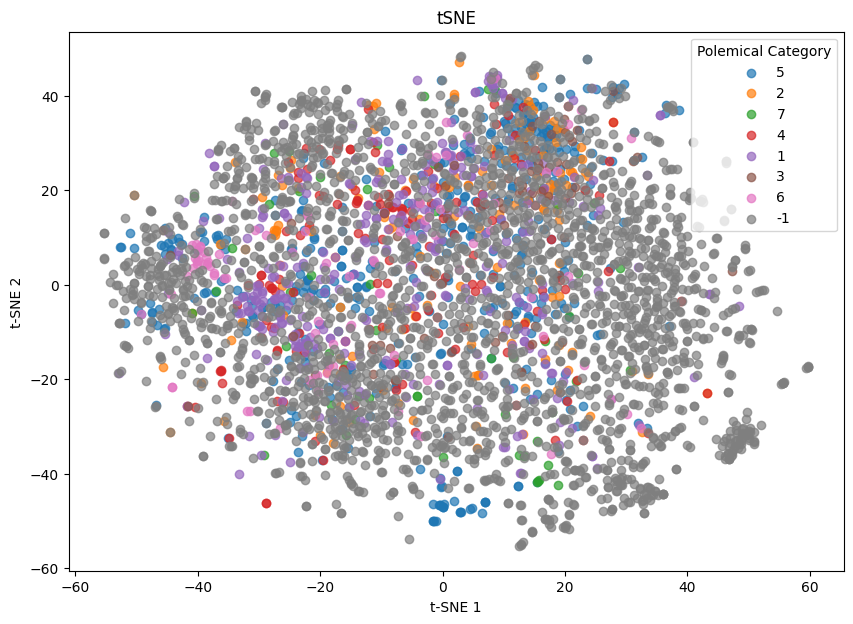

In [160]:
fig = plot_tsne(sentences_annotated_merged, "sent_emb_agbert", "primary_category", perplexity=30)

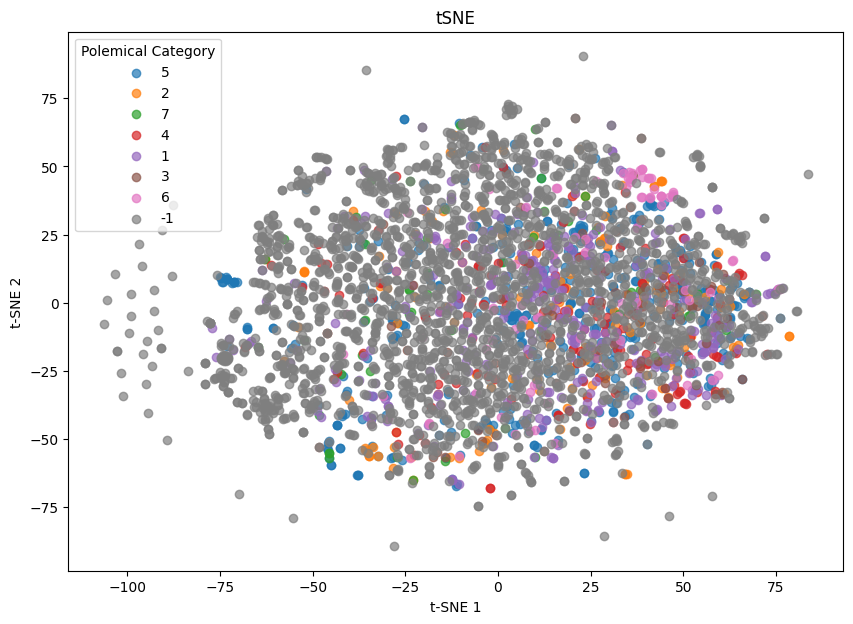

In [161]:
fig = plot_tsne(sentences_annotated_merged, "lem_sent_emb_agbert", "primary_category", perplexity=10)
